# Prova Aprendizado supervisionado

Este notebook é o documento utilizado na cadeira de Aprendizado Supervisonado, administrado pelo professor Alexandre.

## Introdução

Para esta atividade irei implementar o modelo de classificação Logistic Regression manualmente e comparar os resultados com o modelo implementado pela biblioteca scikit-learn.

### Bibliotecas utilizadas

In [1]:
import pandas as pd
import numpy as np
import math
import time

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import train_test_split, GridSearchCV

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score



import matplotlib.pyplot as plt
import seaborn as sns


## 0 - Visualizações

In [2]:
def column_dict(df):

    sns.set_theme(style="white")
    cor_cabecalho = sns.color_palette("Blues_r", n_colors=1)[0]

    df_dict = pd.DataFrame({
        'Coluna': df.columns,
        'Tipo de Variável': [str(t) for t in df.dtypes]
    })

    altura_figura = max(3, len(df_dict) * 0.4)
    fig, ax = plt.subplots(figsize=(6, altura_figura))
    ax.axis('off')

    tabela = ax.table(
        cellText=df_dict.values, 
        colLabels=df_dict.columns, 
        cellLoc='left', 
        loc='center'
    )

    tabela.auto_set_font_size(False)
    tabela.scale(1.2, 1.8)  
    for (linha, coluna), celula in tabela.get_celld().items():
        celula.set_linewidth(0.5)
        
        if linha == 0:
            celula.set_text_props(weight='bold', color='white')
            celula.set_facecolor(cor_cabecalho)
        else:
            if linha % 2 == 0:
                celula.set_facecolor('#f8f9fa')
            else:
                celula.set_facecolor('white')

    plt.title("Estrutura das Variáveis (.info)", fontsize=13, weight='bold', pad=20, loc='left')
    plt.tight_layout()
    plt.show()

    

## 1 - Conhecendo os dados

Foram utilizado os dados provinientes do link do kaggle [Grade Prediction Based on Socioeconomics Factors](https://www.kaggle.com/datasets/chaitanyajamble/grade-prediction-based-on-socioeconomic-factors) e estão armazenos na pasta `data` deste repositório . 

Segue uma breve análise dos dados:



In [3]:


df_original = pd.read_csv('data/student_grade_ses_dataset.csv')

df = df_original.copy()

del df_original




### Visualização target

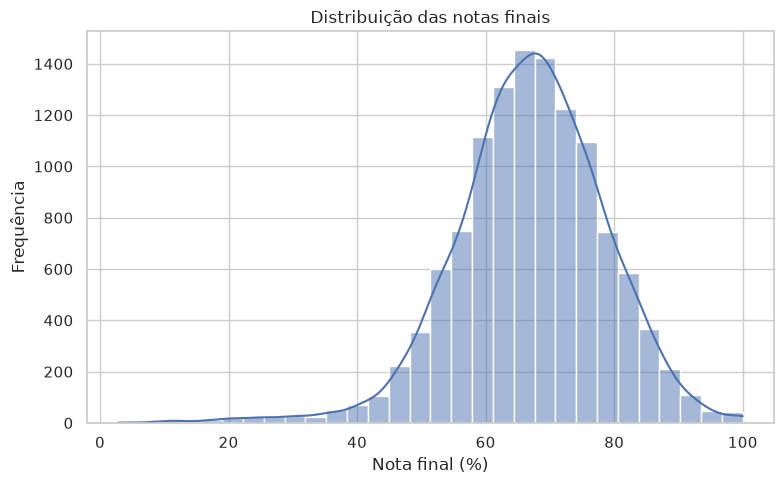

In [4]:

sns.set_theme(style="whitegrid")

plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="final_grade_pct", bins=30, kde=True)
plt.title("Distribuição das notas finais")
plt.xlabel("Nota final (%)")
plt.ylabel("Frequência")
plt.tight_layout()
plt.show()

## 2 - Cleaning +  Preprocessing

In [5]:

def delete_unecessary_columns(df):

    return df.drop(columns=['student_id', 'academic_year', 'survey_date'])

def preprocess_data(df):

    df = delete_unecessary_columns(df)


    # Classificação binária: aprovado (1) ou reprovado (0)
    y = (df['final_grade_pct'] >= 70).astype(int)

    X = df.drop(
        columns=[
            'final_grade_pct', # Nota final
            'grade_class',  # Nota da  classe
            'at_risk_flag' #Risco de reprovar
        ])

    del df

    numerical_cols = X.select_dtypes(include=[np.number]).columns.tolist()
    categorical_cols = X.select_dtypes(include=[str]).columns.tolist()

    numerical_pipeline = Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ])

    categorical_pipeline = Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(handle_unknown='ignore'))
    ])

    preprocessor = ColumnTransformer(
        transformers=[
            ('num', numerical_pipeline, numerical_cols),
            ('cat', categorical_pipeline, categorical_cols)
        ])
    
    X_train, X_temp, y_train, y_temp = train_test_split(
    X, 
    y, 
    test_size=0.2, 
    random_state=42,
    stratify=y
    )

    X_val, X_test, y_val, y_test = train_test_split(
        X_temp,
        y_temp,
        test_size=0.5,
        random_state=42,
        stratify=y_temp
    )

    X_train = preprocessor.fit_transform(X_train)

    X_val = preprocessor.transform(X_val)
    X_test = preprocessor.transform(X_test)

    return X_train, X_val, X_test, y_train, y_val, y_test



In [6]:
X_train, X_val, X_test, y_train, y_val, y_test = preprocess_data(df)


s = pd.Series(y_train)
print(s.value_counts(normalize=True) * 100)  

final_grade_pct
0    59.885655
1    40.114345
Name: proportion, dtype: float64


## 3 - Building Model

### Commons

#### Visualization

In [7]:
def evolution_graphs(model):
    plt.figure(figsize=(8, 5))
    plt.plot(range(len(model.J_history)), model.J_history, color='blue')
    plt.title("Cost Function over Iterations")
    plt.xlabel("Iterations")
    plt.ylabel("Cost")
    plt.grid()
    plt.tight_layout()
    plt.show()


def results(accuracy, precision, recall, f1_score, name):

    metrics = pd.DataFrame({
        "Métrica": [
            "Accuracy",
            "Precision",
            "Recall",
            "F1 Score"
        ],
        "Valor": [
            accuracy,
            precision,
            recall,
            f1_score
        ]})

    fig, ax = plt.subplots(figsize=(6, 2.8))
    ax.axis("off")

    table = ax.table(
        cellText=[
            [metric, f"{value:.2f}"]
            for metric, value in zip(
                metrics["Métrica"],
                metrics["Valor"] * 100 
            )
        ],
        colLabels=["Métrica", "Resultado em %"],
        cellLoc="center",
        colLoc="center",
        loc="center",
        colWidths=[0.55, 0.35]
    )

    table.auto_set_font_size(False)
    table.set_fontsize(11)
    table.scale(1, 1.6)

    ax.set_title(
        f"Resultados — {name}",
        fontsize=13,
        fontweight="bold",
        pad=15
    )

    plt.tight_layout()
    plt.show()


#### Metrics

In [8]:
def metrics(y_true, y_pred):
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, average='weighted', zero_division=0)
    rec = recall_score(y_true, y_pred, average='weighted', zero_division=0)
    f1 = f1_score(y_true, y_pred, average='weighted', zero_division=0)

    return acc, prec, rec, f1

### GridSearch

Implementação do GridSearch para otimizar a seleção dos hiperparâmetros dos modelos 

In [9]:
def hyperparameter_tuning(model, param_grid, X_train, y_train):

    grid_search = GridSearchCV(
        estimator=model,
        param_grid=param_grid,
        scoring='accuracy', 
        cv=5,             
        n_jobs=-1,        
        refit=True
    )

    timer = time.sleep(0.1)

    init_timer = time.perf_counter()
    grid_search.fit(X_train, y_train)
    end_timer = time.perf_counter()

    print("-" * 50, "\n",  f"Training time for {name}: {end_timer - init_timer:.4f} seconds", "\n", "-" * 50,
        "\n", f"Best parameters for {model.__class__.__name__}: {grid_search.best_params_}", "\n", 
        f"Best cross-validation accuracy for {model.__class__.__name__}: {grid_search.best_score_:.4f}", "\n", "x" * 50)

    return grid_search.best_estimator_

### Logistic Regression

#### Descrição

#### 1. Regressão Logística

A Logistic Regression é um algoritmo de aprendizado supervisionado utilizado em problemas de classificação. Neste projeto, o objetivo é realizar uma classificação binária, estimando a probabilidade de uma amostra pertencer à classe positiva (1) ou negativa (0).

O modelo calcula uma combinação linear das características de entrada e aplica a função sigmoid, que transforma o resultado em uma probabilidade entre 0 e 1:

$z = Xw + b$

$
\sigma(z) = \frac{1}{1 + e^{-z}}
$

Em que X representa as características, w os pesos e b o viés (bias).

#### 2. Inicialização dos parâmetros

O método __init__() define os hiperparâmetros utilizados no treinamento:

learning_rate: controla a intensidade dos ajustes realizados nos parâmetros a cada iteração.

num_iterations: determina o número de iterações do algoritmo de otimização.

alpha: controla a intensidade da regularização L2.

Os atributos w e b armazenam os parâmetros aprendidos, enquanto J_history e w_history registram a evolução do custo e dos pesos durante o treinamento.

A herança de BaseEstimator e ClassifierMixin permite integrar a implementação às ferramentas do Scikit-learn, incluindo o GridSearchCV.

#### 3. Função Sigmoid

O método _sigmoid() converte os valores calculados pelo modelo em probabilidades entre 0 e 1. A função np.clip() limita os valores de entrada para reduzir problemas numéricos no cálculo da exponencial.

4. Função de custo e regularização L2

O método _compute_cost() utiliza a Binary Cross-Entropy (BCE) para medir a diferença entre as probabilidades previstas e as classes reais.

A função de custo é complementada pela regularização L2:

$
J(w,b) = J_{\text{BCE}} + \frac{\alpha}{2m}\sum_{j=1}^{n} w_j^2
$

A regularização L2 adiciona uma penalidade aos pesos elevados, ajudando a reduzir o risco de overfitting. O parâmetro alpha controla a intensidade dessa penalização: valores maiores aumentam a regularização. O viés b não é penalizado.

O uso de np.clip() nas probabilidades também evita o cálculo de log(0) durante a avaliação do custo.

#### 5. Cálculo dos gradientes

O método _compute_gradient() calcula as derivadas da função de custo em relação aos pesos e ao viés. Esses gradientes indicam como os parâmetros devem ser ajustados para reduzir o erro.

Na presença da regularização L2, o gradiente dos pesos recebe um termo adicional:

$
\frac{\partial J}{\partial w} = \frac{X^T(\hat{y}-y)}{m} + \frac{\alpha}{m}w
$

Esse termo contribui para manter os pesos menores. Já o gradiente do viés não recebe a penalização.

#### 6. Gradient Descent

O Gradient Descent (Descida do Gradiente) é o algoritmo de otimização responsável por ajustar os pesos e o viés para minimizar a função de custo.

O método _gradient_descent() executa iterativamente o cálculo dos gradientes e a atualização dos parâmetros:

$w \leftarrow w - \eta \frac{\partial J}{\partial w}$

$
b \leftarrow b - \eta \frac{\partial J}{\partial b}
$

Em que (\eta) representa o learning_rate.

Uma taxa de aprendizado muito baixa pode tornar a convergência lenta, enquanto uma taxa muito alta pode dificultar a convergência. Durante o processo, o método também registra periodicamente o custo e os pesos para acompanhar a evolução do treinamento.

#### 7. Treinamento e previsão

O método fit() prepara os dados, inicializa os pesos e o viés com zeros e executa o Gradient Descent. Ao final, armazena os parâmetros aprendidos e os históricos de treinamento.

O método predict_proba() utiliza os parâmetros treinados para calcular as probabilidades da classe positiva. Já o método predict() converte essas probabilidades em classes binárias utilizando um limiar (threshold) de 0,5 por padrão:

Probabilidade maior ou igual a 0,5: classe 1.

Probabilidade menor que 0,5: classe 0.

O limiar pode ser ajustado conforme o objetivo da classificação e a necessidade de equilibrar métricas como precision e recall.

#### 8. Considerações finais

Esta implementação reproduz os principais componentes da Regressão Logística sem utilizar diretamente o classificador pronto do Scikit-learn. Isso permite estudar o cálculo das probabilidades, a função de custo, a otimização por Gradient Descent e os efeitos da regularização L2.

A implementação também possibilita investigar como diferentes hiperparâmetros influenciam o treinamento e comparar o modelo desenvolvido manualmente com a implementação do Scikit-learn.

In [10]:

from sklearn.base import BaseEstimator, ClassifierMixin

class LogisticRegressionScratch(ClassifierMixin, BaseEstimator):

    def __init__(
        self,
        learning_rate=0.01,
        num_iterations=1000,
        alpha=0.01
    ):
        self.learning_rate = learning_rate
        self.num_iterations = num_iterations
        self.alpha = alpha

        self.w = None
        self.b = None
        self.J_history = []
        self.w_history = []

    @staticmethod
    def _sigmoid(z):
        z = np.clip(z, -500, 500)
        return 1 / (1 + np.exp(-z))

    @staticmethod
    def _compute_cost(X, y, w, b, alpha=0.01, **kwargs):

        m = X.shape[0]

        z = X @ w + b
        predictions = LogisticRegressionScratch._sigmoid(z)

        epsilon = 1e-15
        predictions = np.clip(
            predictions, epsilon, 1 - epsilon
        )

        cost = -np.mean(
            y * np.log(predictions)
            + (1 - y) * np.log(1 - predictions)
        )

        l2_penalty = (alpha / (2 * m)) * np.sum(w ** 2) # Regularização L2: não penaliza o viés b

        return cost + l2_penalty

    @staticmethod
    def _compute_gradient( X, y, w, b, alpha=0.01, **argv):

        m = X.shape[0]

        z = np.asarray(X @ w + b).ravel()
        error = LogisticRegressionScratch._sigmoid(z) - y

        dj_dw = np.asarray(X.T @ error).ravel() / m
        dj_db = np.mean(error)

        dj_dw += (alpha / m) * w # Termo adicional da regularização L2
            
        return dj_db, dj_dw

    @staticmethod
    def _gradient_descent( X, y, w_in, b_in,
        cost_function, gradient_function, alpha, learning_rate, num_iters):

        J_history = []
        w_history = []

        log_every = max(1, num_iters // 10)

        for i in range(num_iters):
            dj_db, dj_dw = gradient_function( X, y, w_in, b_in, alpha=alpha)

            w_in -= learning_rate * dj_dw
            b_in -= learning_rate * dj_db

            if (i + 1) % log_every == 0 or i == num_iters - 1:
                cost = cost_function(X, y, w_in, b_in, alpha=alpha)
                J_history.append(cost)
                w_history.append(w_in.copy())

        return w_in, b_in, J_history, w_history 

    def fit(self, X, y):

        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float).reshape(-1)

        self.classes_ = np.unique(y)
        self.n_features_in_ = X.shape[1]

        initial_w = np.zeros(X.shape[1])
        initial_b = 0.0

        self.w, self.b, self.J_history, self.w_history = self._gradient_descent(
            X=X,
            y=y,
            w_in=initial_w,
            b_in=initial_b,
            cost_function=self._compute_cost,
            gradient_function=self._compute_gradient,
            alpha=self.alpha,
            learning_rate=self.learning_rate,
            num_iters=self.num_iterations
        )

        return self

    def predict_proba(self, X):
        if self.w is None:
            raise ValueError("O modelo precisa ser treinado antes da previsão.")

        X = np.asarray(X, dtype=float)

        return self._sigmoid(X @ self.w + self.b)

    def predict(self, X, threshold=0.4):  
        probabilities = self.predict_proba(X)

        return (probabilities >= threshold).astype(int)

-------------------------------------------------- 
 Training time for Logistic Regression (sklearn): 18.2320 seconds 
 -------------------------------------------------- 
 Best parameters for LogisticRegression: {'C': 0.05, 'max_iter': 1000} 
 Best cross-validation accuracy for LogisticRegression: 0.7304 
 xxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxx
-------------------------------------------------- 
 Training time for Logistic Regression (Scratch): 638.9862 seconds 
 -------------------------------------------------- 
 Best parameters for LogisticRegressionScratch: {'alpha': 0.0001, 'learning_rate': 0.1, 'num_iterations': 10000} 
 Best cross-validation accuracy for LogisticRegressionScratch: 0.7178 
 xxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxx


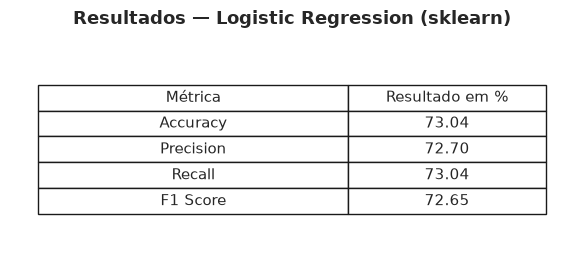

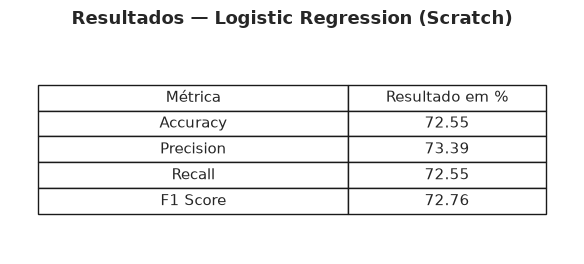

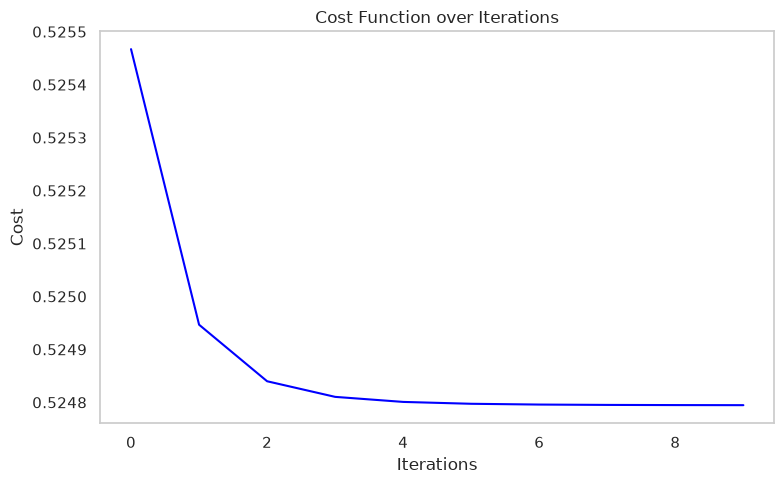

In [11]:

candidate_models = {
    "Logistic Regression (sklearn)": LogisticRegression(max_iter=1000),
    "Logistic Regression (Scratch)": LogisticRegressionScratch(learning_rate=0.01, num_iterations=1000, alpha=0.01)
}

best_model = next(iter(candidate_models.values()), LogisticRegression( max_iter=1000)) #First model
best_model_name = next(iter(candidate_models), "Logistic Regression (sklearn)") #First model name
best_rec = 0.0

param_grids = {
    "Logistic Regression (sklearn)": {
        "C": [10.0, 0.0001, 0.0005, 0.005, 0.05, 0.5, 5, 50, 500],
        "max_iter": [1000, 3000, 5000]
    },
    "Logistic Regression (Scratch)": {
        "learning_rate": [0.001, 0.0005, 0.1],
        "num_iterations": [1000, 10000],
        "alpha": [0.0001, 0.001, 0.01, 0.1]
    }
}

for name, model in candidate_models.items():
    candidate_models[name] = hyperparameter_tuning(
        model=model,
        param_grid=param_grids[name],
        X_train=X_train,
        y_train=y_train
    )


for name, model in candidate_models.items():

    val_preds = model.predict(X_val)  # threshold  baixo para reduzir FN -> maior recall

    val_acc, val_prec, val_rec, val_f1 = metrics(y_val, val_preds)
    
    if val_rec > best_rec:
        best_rec = val_rec
        best_model = model
        best_model_name = name

    results(val_acc, val_prec, val_rec, val_f1, name)

    if '(Scratch)' in name : evolution_graphs(model)

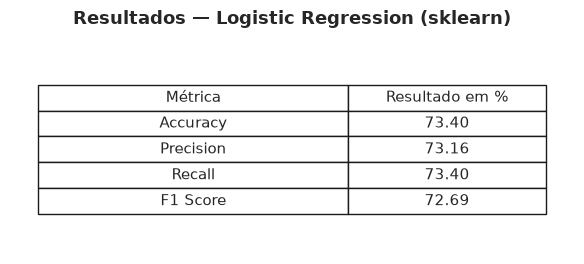

In [12]:

y_test_pred =  best_model.predict(X_test)

model_acc, model_prec, model_rec, model_f1 = metrics(y_test, y_test_pred)


results(model_acc, model_prec, model_rec, model_f1, best_model_name)


# TODO ->  Revisar O modelo Logistic REgression, explicando o que é learning rate, como o gradient descent funciona,  como a função custo opera, o que é alpha e como a normalização L2 funciona ( Explicando a diferença de alpha e C [sklearn])